# Iceberg iz cistog Python-a (PyIceberg + DuckDB)

Ovaj notebook ne koristi Spark ni JVM. PyIceberg cita **isti REST katalog** i **iste Parquet fajlove na S3** koje je napisao Spark,
a DuckDB nad njima izvrsava SQL. Ovo je dokaz da je tabela otvoren format, a ne interni format jedne masine.

In [1]:
import sys; sys.path.insert(0, "/app/explorer")
import pandas as pd
import lake
pd.set_option("display.max_colwidth", 80)
cat = lake.catalog()
{ns[0]: [t[1] for t in cat.list_tables(ns)] for ns in cat.list_namespaces()}

{'analytics': ['conversion_funnel',
  'customer_360',
  'daily_sales',
  'dim_customer',
  'dim_date',
  'dim_product',
  'fact_order_items',
  'payment_reconciliation'],
 'audit': ['maintenance_log', 'wap_log'],
 'bench': ['events', 'growth', 'rb', 'upd_cow', 'upd_mor', 'v3_probe'],
 'clean': ['clickstream',
  'clickstream_rejected',
  'order_items',
  'orders',
  'payments'],
 'demo': ['clickstream_copy', 'concurrent_writes'],
 'ml': ['customer_segments'],
 'raw': ['clickstream',
  'customers',
  'fx_rates',
  'order_items',
  'orders',
  'payments',
  'products']}

## 1. Tabela = metapodaci
Sema, specifikacija particija, redosled sortiranja i svojstva zapisani su u `metadata.json`, ne u masini za obradu.

In [2]:
fact = lake.table("analytics.fact_order_items")
print("metadata.json:", fact.metadata_location)
print("format:", fact.format_version)
print(fact.schema())
print("particije:", fact.spec())
print("sortiranje:", fact.sort_order())
{k: v for k, v in fact.properties.items() if k.startswith("write.")}

metadata.json: s3://warehouse/analytics/fact_order_items/metadata/00018-4911c072-d2c8-4776-8275-2fd1bc868f7d.metadata.json
format: 2
table {
  1: order_item_id: optional long
  2: order_id: optional long
  3: customer_key: optional long
  4: product_key: optional long
  5: order_ts: optional timestamptz
  6: sales_channel: optional string
  7: country: optional string
  8: quantity: optional int
  9: unit_price: optional decimal(12, 2)
  10: discount_amount: optional decimal(10, 2)
  15: discount_pct: optional decimal(5, 2)
  11: net_amount: optional decimal(12, 2)
  12: currency: optional string
  13: net_amount_eur: optional decimal(12, 2)
  14: order_status: optional string
}
particije: [
  1000: order_ts_month: month(5)
]
sortiranje: [
  5 ASC NULLS FIRST
]


{'write.merge.mode': 'copy-on-write',
 'write.delete.mode': 'copy-on-write',
 'write.parquet.compression-codec': 'zstd',
 'write.update.mode': 'copy-on-write',
 'write.distribution-mode': 'range'}

## 2. Snimci (snapshots) i reference (grane, tagovi)
Svaki upis je novi snimak; tagovi trajno imenuju snimak (npr. zatvaranje meseca, skup za ucenje modela).

In [3]:
fact.inspect.snapshots().select(["committed_at", "snapshot_id", "parent_id", "operation"]).to_pandas()

,committed_at,snapshot_id,parent_id,operation
0,2026-10-10 17:00:57.576,7200023244801314661,3971751992937817810,overwrite
1,2026-10-10 17:06:54.979,2657184702488358473,7184199836369485738,overwrite


In [4]:
fact.inspect.refs().to_pandas()

,name,type,snapshot_id,max_reference_age_in_ms,min_snapshots_to_keep,max_snapshot_age_in_ms
0,ml-train-20261010,TAG,7200023244801314661,NaN,NaN,NaN
1,main,BRANCH,2657184702488358473,NaN,NaN,NaN
2,pre-deploy,TAG,7200023244801314661,NaN,NaN,NaN
3,close-2026-09,TAG,7200023244801314661,3.153600e+10,NaN,NaN


## 3. Planiranje upita: odsecanje particija i fajlova (pruning)
Pre citanja ijednog bajta podataka, PyIceberg iz manifesta zna koje fajlove treba procitati:
particija (mesec) i min/max statistike kolona po fajlu.

In [5]:
all_files = list(fact.scan().plan_files())
sept = list(fact.scan(row_filter="order_ts >= '2026-09-01T00:00:00+00:00' AND order_ts < '2026-10-01T00:00:00+00:00'").plan_files())
one_day = list(fact.scan(row_filter="order_ts >= '2026-09-15T00:00:00+00:00' AND order_ts < '2026-09-16T00:00:00+00:00'").plan_files())
pd.DataFrame({"upit": ["cela tabela", "septembar", "jedan dan"],
              "fajlova za citanje": [len(all_files), len(sept), len(one_day)],
              "MB": [round(sum(t.file.file_size_in_bytes for t in x) / 1e6, 2) for x in (all_files, sept, one_day)]})

,upit,fajlova za citanje,MB
0,cela tabela,2,0.41
1,septembar,1,0.15
2,jedan dan,1,0.15


## 4. SQL nad Iceberg tabelama u DuckDB-u

In [6]:
con = lake.duck({"fact": "analytics.fact_order_items", "product": "analytics.dim_product"})
con.sql("""
    SELECT p.category, COUNT(DISTINCT f.order_id) AS orders, ROUND(SUM(f.net_amount_eur), 2) AS revenue_eur
    FROM fact f JOIN product p ON f.product_key = p.product_key
    WHERE f.order_status IN ('paid', 'shipped', 'delivered')
    GROUP BY 1 ORDER BY revenue_eur DESC""").df()

,category,orders,revenue_eur
0,Laptops,2653,3723323.05
1,Smartphones,4068,2537542.99
2,Home Appliances,2101,1327481.31
3,Gaming,3004,681896.51
4,Smart Home,1857,253785.28
5,Audio,1661,253195.65
6,Accessories,2788,142434.02


## 5. Time travel
Isti upit nad prvim snimkom tabele i nad tekucim stanjem.

In [7]:
first = min(fact.metadata.snapshots, key=lambda s: s.timestamp_ms).snapshot_id
q = "SELECT COUNT(*) AS stavki, ROUND(SUM(net_amount_eur), 2) AS revenue_eur FROM fact"
con_then = lake.duck({"fact": "analytics.fact_order_items"}, ref={"fact": first})
con_now = lake.duck({"fact": "analytics.fact_order_items"})
then = con_then.sql(q).df().assign(verzija=f"snimak {first}")
now = con_now.sql(q).df().assign(verzija="tekuca")
pd.concat([then, now])

,stavki,revenue_eur,verzija
0,21856,9509124.15,snimak 7200023244801314661
0,21746,9465863.96,tekuca


## 6. Fajlovi i manifesti
`inspect.files()` je sadrzaj manifesta tekuceg snimka: putanja, broj redova, velicina i statistike kolona.

In [8]:
fact.inspect.files().select(["content", "file_path", "record_count", "file_size_in_bytes"]).to_pandas()

,content,file_path,record_count,file_size_in_bytes
0,0,s3://warehouse/analytics/fact_order_items/data/order_ts_month=2026-09/00000-...,7746,149752
1,0,s3://warehouse/analytics/fact_order_items/data/order_ts_month=2026-10/00000-...,14000,263815


In [9]:
fact.inspect.manifests().select(["path", "added_snapshot_id", "added_data_files_count", "existing_data_files_count", "deleted_data_files_count"]).to_pandas()

,path,added_snapshot_id,added_data_files_count,existing_data_files_count,deleted_data_files_count
0,s3://warehouse/analytics/fact_order_items/metadata/cc0b20b1-d77b-4b8c-8ac1-2...,2657184702488358473,2,0,0
1,s3://warehouse/analytics/fact_order_items/metadata/cc0b20b1-d77b-4b8c-8ac1-2...,2657184702488358473,0,0,2


## 7. Merge-on-read: delete fajlovi
`raw.orders` je merge-on-read: izmena reda ne prepisuje data fajl, vec dodaje mali *position delete* fajl
("red 17 u fajlu X vise ne vazi"). Citalac spaja data i delete fajlove u letu; kompakcija ih kasnije spaja trajno.

In [10]:
orders = lake.table("raw.orders")
f = orders.inspect.files().to_pandas()
f["vrsta"] = f.content.map({0: "data", 1: "position deletes", 2: "equality deletes"})
f.groupby("vrsta").agg(fajlova=("file_path", "count"), redova=("record_count", "sum"), bajtova=("file_size_in_bytes", "sum"))

,fajlova,redova,bajtova
vrsta,,,
data,1,10906,152306


## 8. Struktura metapodataka (pandan slici 3.3)
katalog -> metadata.json -> snimci -> lista manifesta -> manifesti -> data/delete fajlovi

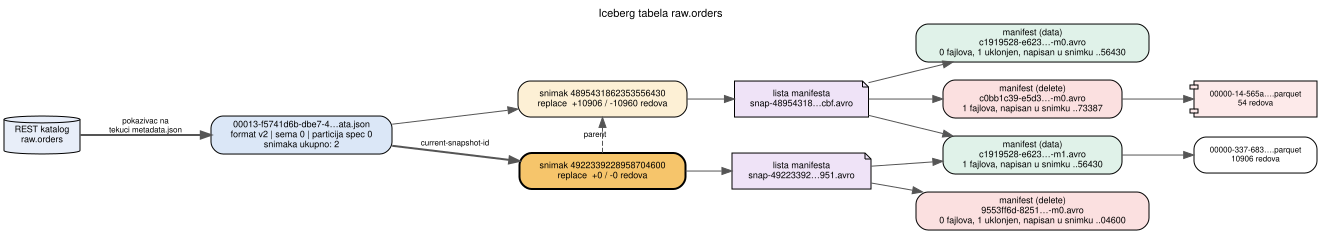

In [11]:
import metadata_graph
metadata_graph.build("raw.orders", 3)